# This is WGS project exercise for bacterial WGS_varianti analysis

In [1]:
import sys
print(sys.executable)

/home/julha_07/miniforge3/envs/bacterial_wgs/bin/python


## Import the dependables
`For this exercise, we need pandas and matplotlib`

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

## Define the pathway, file, place in a dataframe.
Here "\t" seperates the information into columns, header none meaning it is a tab format file and not a csv, it prohibiti to use the first row as the header.

In [5]:
Path = "/home/julha_07/bacterial-wgs-project/results/"
file= "coverage.tsv"

In [7]:
df = pd.read_csv(Path+file, sep= "\t", header=None, 
                names = ["chromosome","position","depth"])
df.head()

,chromosome,position,depth
0,Wildtype,1,0
1,Wildtype,2,0
2,Wildtype,3,0
3,Wildtype,4,0
4,Wildtype,5,0


## Calcuate basic stat info:

In [8]:
print('Mean depth:', round(df.depth.mean(),2))
print ('Median depth:', df.depth.median())
print ('Maximum depth:', df.depth.max())

Mean depth: 18.96
Median depth: 19.0
Maximum depth: 57


In [16]:
df['window'] = (df['position'] - 1) // 10000
windows = (df.groupby(['chromosome', 'window'], as_index = False).agg(mean_depth=('depth', 'mean')))

windows.head()

,chromosome,window,mean_depth
0,Wildtype,0,19.3387
1,Wildtype,1,20.4001
2,Wildtype,2,20.3618
3,Wildtype,3,28.2505
4,Wildtype,4,25.7722


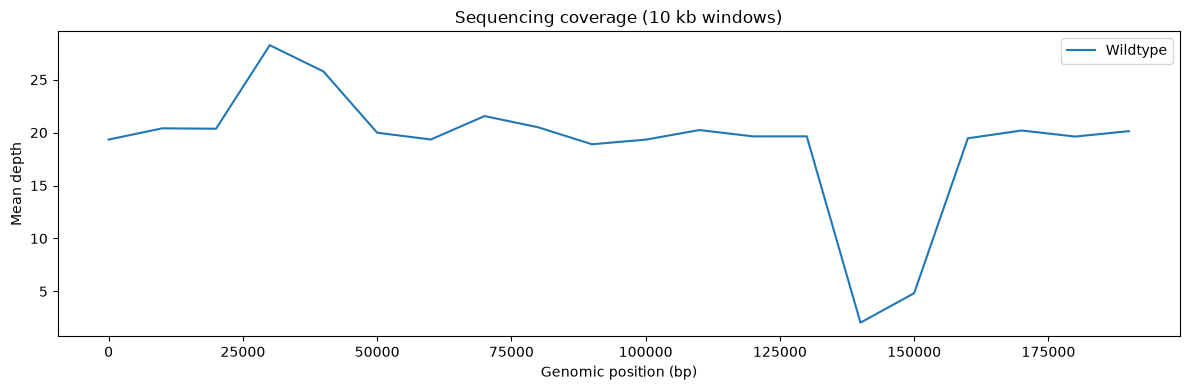

In [25]:
fig, ax = plt.subplots(figsize=(12, 4))
for chrom, sub in windows.groupby('chromosome'):
    ax.plot(sub['window']* 10000, sub['mean_depth'], label=chrom)
ax.set(xlabel='Genomic position (bp)', ylabel='Mean depth',
       title='Sequencing coverage (10 kb windows)')
ax.legend()
fig.tight_layout()
fig.savefig('results/coverage_plot.png', dpi=300)

In [22]:
low_region = df[
    (df['position'] >= 130000) &
    (df['position'] <= 160000)
]

print(low_region['depth'].describe())

count    30001.000000
mean         8.841272
std         10.425929
min          0.000000
25%          0.000000
50%          0.000000
75%         19.000000
max         37.000000
Name: depth, dtype: float64


In [23]:
zero_coverage = (low_region['depth']== 0).sum()
print("Position with zero coverage:", zero_coverage)
print("Percentage with zero coverage:", 
     round(zero_coverage/len(low_region) * 100, 2))

Position with zero coverage: 16715
Percentage with zero coverage: 55.71
